# Task 05: Deep Learning / NLP Text Classifier

**Internship:** RabTech Academy

## Project: SMS Spam Detection Using Deep Learning

### Objective
To develop a deep learning-based NLP text classification system using TensorFlow/Keras.

The project includes text preprocessing, tokenization, vectorization, neural network construction, model training, validation, performance visualization and prediction on unseen text messages.

### Framework
TensorFlow / Keras

In [26]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("TensorFlow is ready!")

TensorFlow version: 2.21.0
TensorFlow is ready!


In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

All libraries imported successfully!
TensorFlow version: 2.21.0


In [28]:
# SMS Spam Collection dataset
url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"

df = pd.read_csv(
    url,
    sep="\t",
    header=None,
    names=["label", "message"]
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [29]:
print("Dataset Information:")
df.info()

print("\nDataset Description:")
display(df.describe(include="all"))

print("\nFirst 5 Messages:")
display(df.head())

print("\nLabel Distribution:")
print(df["label"].value_counts())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Dataset Description:


,label,message
count,5572,5572
unique,2,5169
top,ham,"Sorry, I'll call later"
freq,4825,30



First 5 Messages:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



Label Distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


In [30]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

# Remove missing and duplicate records
df = df.dropna()
df = df.drop_duplicates()

print("\nCleaned Dataset Shape:", df.shape)

Missing Values:
label      0
message    0
dtype: int64

Duplicate Records: 403

Cleaned Dataset Shape: (5169, 2)


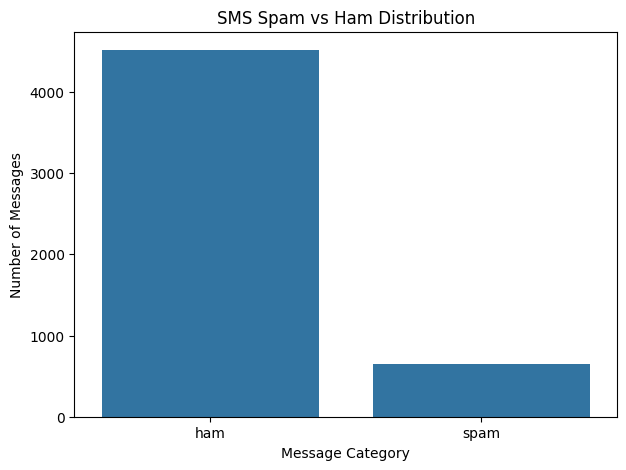

In [31]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="label")

plt.title("SMS Spam vs Ham Distribution")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")

plt.show()

In [32]:
# Ham = 0
# Spam = 1

df["label_encoded"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

print(df[["label", "label_encoded"]].head())

print("\nTarget distribution:")
print(df["label_encoded"].value_counts())

  label  label_encoded
0   ham              0
1   ham              0
2  spam              1
3   ham              0
4   ham              0

Target distribution:
label_encoded
0    4516
1     653
Name: count, dtype: int64


In [33]:
X = df["message"].astype(str).values
y = df["label_encoded"].values

print("Messages:", X.shape)
print("Labels:", y.shape)

Messages: (5169,)
Labels: (5169,)


In [34]:
# First split: 80% training, 20% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second split: 10% validation, 10% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 4135
Validation samples: 517
Testing samples: 517


In [35]:
# Define vocabulary size and sequence length
max_tokens = 10000
sequence_length = 100

# Create TextVectorization layer
vectorizer = layers.TextVectorization(
    max_tokens=max_tokens,
    output_mode="int",
    output_sequence_length=sequence_length
)

# Adapt only on training messages
vectorizer.adapt(
    tf.data.Dataset.from_tensor_slices(X_train).batch(64)
)

print("Text vectorization completed!")

print("\nVocabulary size:")
print(len(vectorizer.get_vocabulary()))

# Example
sample_text = tf.constant(["Congratulations! You won a free prize"])
print("\nVectorized sample:")
print(vectorizer(sample_text).numpy())

Text vectorization completed!

Vocabulary size:
8471

Vectorized sample:
[[810   4 195   6  56 149   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]]


In [36]:
model = models.Sequential([
    layers.Input(shape=(), dtype=tf.string),

    # Text preprocessing
    vectorizer,

    # Embedding layer
    layers.Embedding(
        input_dim=max_tokens,
        output_dim=64,
        mask_zero=True
    ),

    # Pooling
    layers.GlobalAveragePooling1D(),

    # Batch normalization
    layers.BatchNormalization(),

    # Hidden layer
    layers.Dense(64, activation="relu"),

    # Dropout
    layers.Dropout(0.5),

    # Output layer
    layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization_1            │ (None, 100)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_2 (Embedding)         │ (None, 100, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_2      │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 644,481 (2.46 MB)

 Trainable params: 644,353 (2.46 MB)

 Non-trainable params: 128 (512.00 B)

In [37]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [38]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

print("Early stopping configured successfully!")

Early stopping configured successfully!


In [39]:
history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping],
    verbose=1
)

print("Model training completed!")

Epoch 1/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.8537 - loss: nan - val_accuracy: 0.8723 - val_loss: nan
Epoch 2/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8738 - loss: nan - val_accuracy: 0.8723 - val_loss: nan
Epoch 3/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8738 - loss: nan - val_accuracy: 0.8723 - val_loss: nan
Epoch 4/15
130/130 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8738 - loss: nan - val_accuracy: 0.8723 - val_loss: nan
Model training completed!


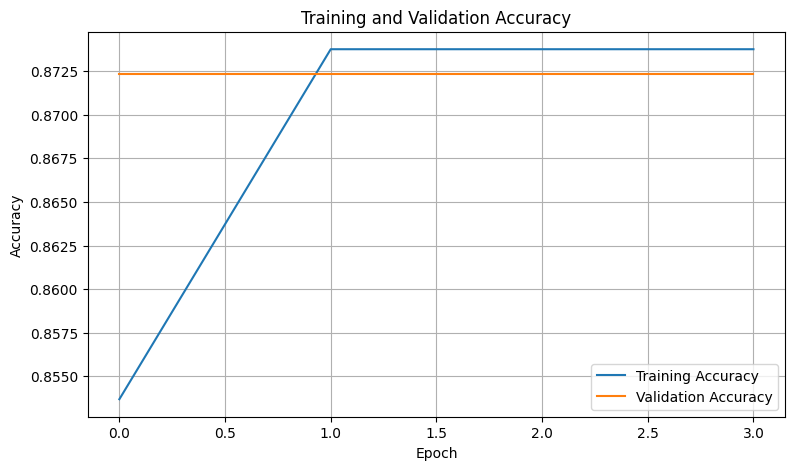

In [40]:
plt.figure(figsize=(9, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid()
plt.show()

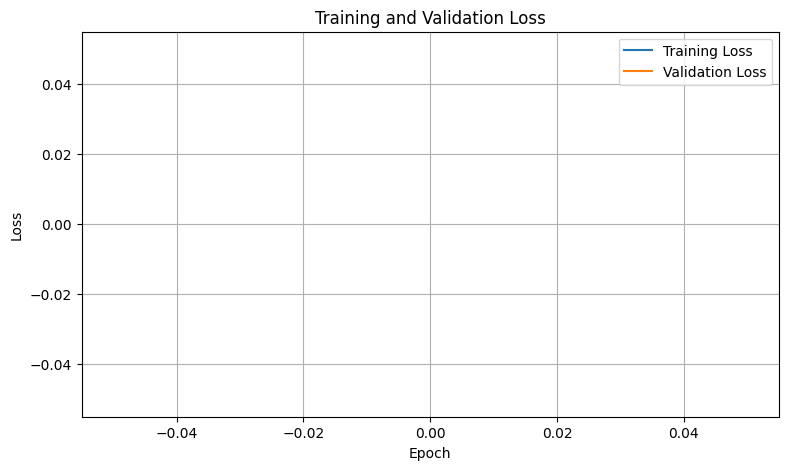

In [41]:
plt.figure(figsize=(9, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid()
plt.show()

In [42]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

Test Loss: nan
Test Accuracy: 0.8742746710777283


In [43]:
# Predict probabilities
y_prob = model.predict(X_test).ravel()

# Convert probabilities into binary predictions
y_pred = (y_prob >= 0.5).astype(int)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Ham", "Spam"]
))

17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
Accuracy: 0.874274661508704
Precision: 0.0
Recall: 0.0
F1 Score: 0.0

Classification Report:
              precision    recall  f1-score   support

         Ham       0.87      1.00      0.93       452
        Spam       0.00      0.00      0.00        65

    accuracy                           0.87       517
   macro avg       0.44      0.50      0.47       517
weighted avg       0.76      0.87      0.82       517



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_

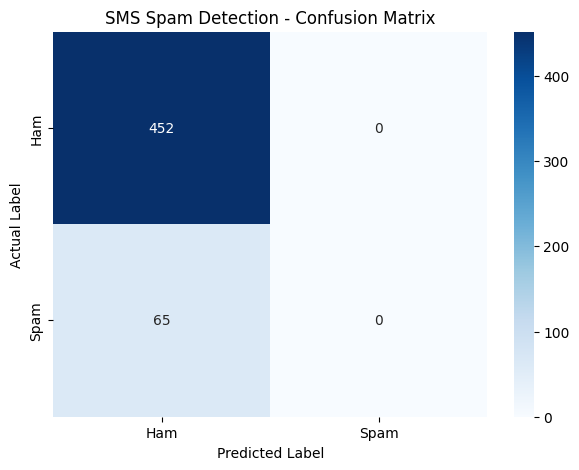

In [44]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("SMS Spam Detection - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [45]:
# New messages that were not used for training
new_messages = [
    "Congratulations! You have won a free lottery prize. Call now!",
    "Hey, are we meeting for lunch today?",
    "URGENT! You have won a free gift voucher!",
    "Please send me the assignment before tomorrow."
]

# Convert to a TensorFlow string tensor instead of a NumPy array to avoid dtype issues
predictions = model.predict(
    tf.convert_to_tensor(new_messages, dtype=tf.string)
).ravel()

for message, probability in zip(new_messages, predictions):
    label = "SPAM" if probability >= 0.5 else "HAM"
    confidence = (
        probability if probability >= 0.5
        else 1 - probability
    )

    print("\nMessage:", message)
    print("Prediction:", label)
    print("Confidence:", f"{confidence * 100:.2f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step

Message: Congratulations! You have won a free lottery prize. Call now!
Prediction: HAM
Confidence: nan%

Message: Hey, are we meeting for lunch today?
Prediction: HAM
Confidence: nan%

Message: URGENT! You have won a free gift voucher!
Prediction: HAM
Confidence: nan%

Message: Please send me the assignment before tomorrow.
Prediction: HAM
Confidence: nan%


In [46]:
model.save("RabTech_Task05_SMS_Spam_Classifier.keras")

print("Deep learning model saved successfully!")

Deep learning model saved successfully!


## Observations

1. The SMS dataset contains both Spam and Ham messages.
2. TextVectorization was used for tokenization and numerical representation.
3. An Embedding layer was used to learn text representations.
4. Batch Normalization helped stabilise training.
5. Dropout was used to reduce overfitting.
6. Early Stopping was implemented to monitor validation loss.
7. Training and validation accuracy and loss curves were plotted.
8. The model was evaluated using accuracy, precision, recall and F1-score.
9. Unseen SMS messages were classified with prediction confidence.

## Conclusion

The experiment successfully demonstrates a deep learning-based NLP text classification system using TensorFlow/Keras.

A neural network was developed to classify SMS messages as Spam or Ham. Text preprocessing, embedding, Batch Normalization, Dropout and Early Stopping were implemented.

The model was evaluated using test data, and its training performance was visualised using accuracy and loss curves. Finally, the trained model was tested on unseen messages to demonstrate classification and prediction confidence.

This experiment demonstrates the practical application of deep learning and Natural Language Processing in spam detection.